### **Unsupervised Learning - Data Center Archetypes**

Using multiple clustering models, we'll attempt to identify possible facility archetypes from the cleaned, standardized, and feature engineered FracTracker dataset.

In [1]:
import pandas as pd
import numpy as np
from itertools import product
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [3]:
# Load cleaned data
cleaned_data = pd.read_csv('./data/processed/fractracker_data_centers_with_eia_cleaned.csv')

cleaned_data[['facility_name', 'state', 'sizerank', 'facility_size_sqft', 'property_size_acres']].head()

,facility_name,state,sizerank,facility_size_sqft,property_size_acres
0,Stak Energy Data Center,AK,"Mega campus (>1,000 MW)",NaN,715.00
1,Prudhoe Bay Data Center,AK,Hyperscale (100-999 MW),NaN,100.00
2,Project Marvel,AL,"Mega campus (>1,000 MW)","4,500,000.00","1,600.00"
3,BHM01 Nebius Data Center,AL,Hyperscale (100-999 MW),NaN,80.00
4,DC Blox,AL,Unknown,NaN,NaN


#### **Feature Availability**

We first examined the completeness of candidate features. Some complete columns contain encoded missing values. For example, `sizerank_numeric` uses 1 to represent an Unknown capacity category. The EIA-derived variables also provide information about nearby electricity generation and county-level electricity consumption and pricing.

In [4]:
features = [
    "sizerank_numeric",
    'facility_size_sqft', 
    'property_size_acres', 
    'project_cost', 
    'power_source',
    'cooling_source',
    'cooling_type',
    'generator_count',
    'generator_capacity_summer',
    'summer_Cents/kWh.1',
    'summer_Megawatthours.1',
    'Capacity_Sum'
]

availability = pd.DataFrame({
    'non_null': cleaned_data[features].notna().sum(),
    'percent_available': cleaned_data[features].notna().mean().mul(100).round(1)
})

availability.sort_values('percent_available', ascending=False)

,non_null,percent_available
sizerank_numeric,1720,100.00
summer_Megawatthours.1,1719,99.90
summer_Cents/kWh.1,1719,99.90
generator_count,1594,92.70
Capacity_Sum,1594,92.70
generator_capacity_summer,1594,92.70
facility_size_sqft,1043,60.60
property_size_acres,1033,60.10
project_cost,330,19.20
power_source,174,10.10


#### **Distribution of Capacity (Size Rank)**

A large share of the facilities retained after the initial size filter have an Unknown capacity classification. 

The size-rank field is encoded using the following values:

| Capacity | Numeric Value |
|---|---:|
| Unknown | 1 |
| Small (0–10 MW) | 2 |
| Medium (11–50 MW) | 3 |
| Large (51–99 MW) | 4 |
| Hyperscale (100–999 MW) | 5 |
| Mega campus (>1,000 MW) | 6 |

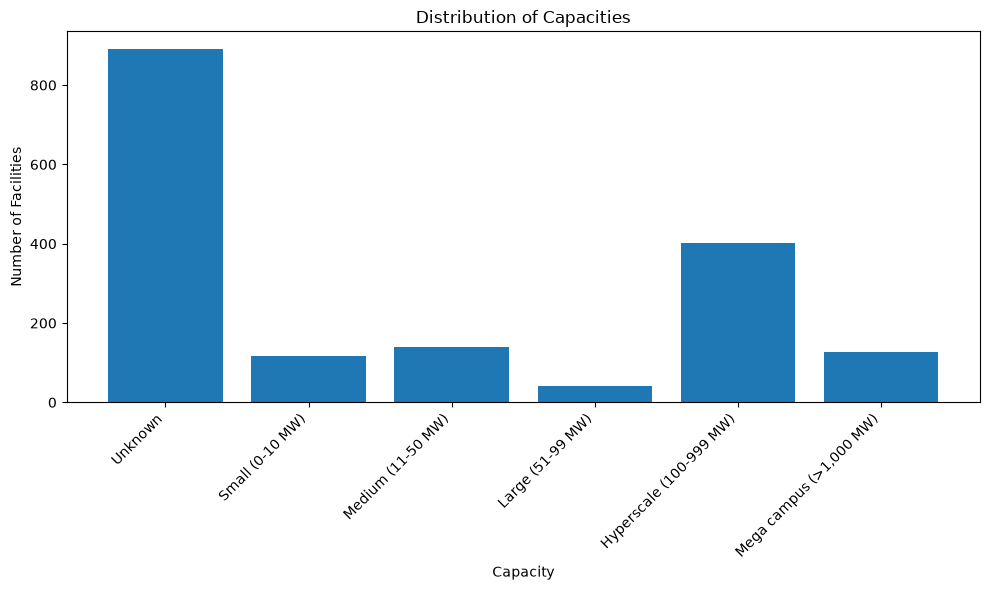

In [5]:
size_rank = {
    "Unknown": 1,
    "Small (0-10 MW)": 2,
    "Medium (11-50 MW)": 3,
    "Large (51-99 MW)": 4,
    "Hyperscale (100-999 MW)": 5,
    "Mega campus (>1,000 MW)": 6
}

# Arrange categories using capacity
size_counts = (
    cleaned_data["sizerank"]
    .value_counts()
    .reindex(size_rank.keys(), fill_value=0)
)

plt.figure(figsize=(10, 6))
plt.bar(size_counts.index, size_counts.values)

plt.title("Distribution of Capacities")
plt.xlabel("Capacity")
plt.ylabel("Number of Facilities")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### **Size Distributions**

This chart examines the distributions of facility size (square feet) and property size (acres) to better understand the variation in physical size across data centers. 

Both distributions are heavily right-skewed:
- Most data centers concentrated at smaller sizes
- A small number of exceptionally large facilities 

By capping values at the 99th percentile, we can reduce the visual impact of these extreme values and gain a clearer understanding of how most facilities are distributed. However, this is only for the purpose of visualization and is not included in the model pipeline.

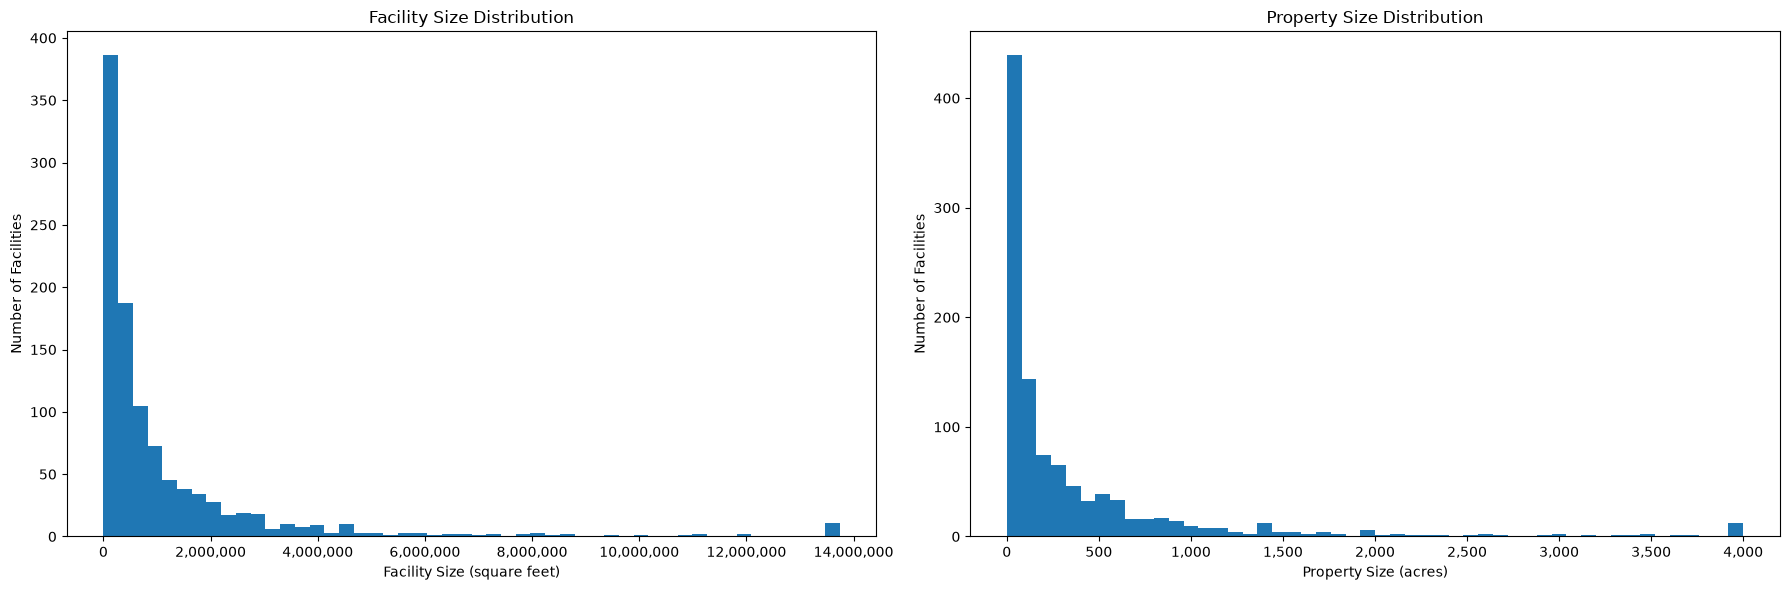

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].hist(
    cleaned_data["facility_size_sqft"].clip(
        upper=cleaned_data["facility_size_sqft"].quantile(0.99)
    ),
    bins=50
)
axes[0].set_title("Facility Size Distribution")
axes[0].set_xlabel("Facility Size (square feet)")
axes[0].set_ylabel("Number of Facilities")

axes[1].hist(
    cleaned_data["property_size_acres"].clip(
        upper=cleaned_data["property_size_acres"].quantile(0.99)
    ),
    bins=50
)
axes[1].set_title("Property Size Distribution")
axes[1].set_xlabel("Property Size (acres)")
axes[1].set_ylabel("Number of Facilities")

axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

plt.tight_layout()
plt.show()

#### **Correlation Matrix**

Spearman correlation analysis revealed strong positive relationships among facility size features. These findings are consistent with expectations, as larger properties generally accommodate larger facilities, which may also require greater power capacity (MW). Retaining them enables a better description of scale, but it may also increase the influence of facility size on the resulting groups.

In [7]:
features = [
    "sizerank_numeric",
    "facility_size_sqft",
    "property_size_acres",
    'generator_count',
    'summer_Cents/kWh.1',
    'summer_Megawatthours.1',
    'Capacity_Sum'
]

# Remove 'Unknown' data centers
corr_analysis = cleaned_data.loc[cleaned_data['sizerank_numeric'] != 1]

corr_analysis[features].corr(method='spearman')

,sizerank_numeric,facility_size_sqft,property_size_acres,generator_count,summer_Cents/kWh.1,summer_Megawatthours.1,Capacity_Sum
sizerank_numeric,1.00,0.83,0.71,-0.26,-0.10,-0.09,0.07
facility_size_sqft,0.83,1.00,0.78,-0.26,-0.07,-0.02,0.08
property_size_acres,0.71,0.78,1.00,-0.27,-0.06,-0.17,-0.05
generator_count,-0.26,-0.26,-0.27,1.00,0.18,0.12,0.52
summer_Cents/kWh.1,-0.10,-0.07,-0.06,0.18,1.00,-0.43,-0.05
summer_Megawatthours.1,-0.09,-0.02,-0.17,0.12,-0.43,1.00,0.15
Capacity_Sum,0.07,0.08,-0.05,0.52,-0.05,0.15,1.00


#### **Feature Selection & Scaling**

Given the limited availability of several potentially informative features, including cooling source, power source, cooling type, and project cost, these attributes were excluded from the analysis. Additionally, observations with insufficient data for the selected features were removed rather than relying on extensive imputation, which could introduce artificial patterns which may influence the resulting clusters. 

The features ultimately selected for modeling include:

- sizerank_numeric
- facility_size_sqft 
- property_size_acres 
- generator_count 
- summer_Cents/kWh.1 
- summer_Megawatthours.1
- Capacity_Sum

Numerical features have also been transformed and scaled to reduce the disproportionate influence of larger values and improve comparability across features. Although these decisions reduced the number of data centers included in the analysis and may limit the representativeness of the results, they were intended to improve clustering reliability. 

In [8]:
selected_features = [
    "sizerank_numeric",
    "facility_size_sqft",
    "property_size_acres",
    'generator_count',
    'summer_Cents/kWh.1',
    'summer_Megawatthours.1',
    'Capacity_Sum'
]

cleaned_data = cleaned_data[selected_features].copy()

# Treat unknown size rank as missing
cleaned_data["sizerank_numeric"] = (
    cleaned_data["sizerank_numeric"].replace(1, np.nan)
)

# Remove missing values
cleaned_data = cleaned_data.dropna()

# Log transform right skewed features
log_features = [
    "facility_size_sqft",
    "property_size_acres",
    'generator_count',
    'summer_Cents/kWh.1', 
    'summer_Megawatthours.1',
    'Capacity_Sum'
]

cleaned_data[log_features] = np.log1p(cleaned_data[log_features])

# Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cleaned_data)

print(f"{len(X_scaled)} data centers")

256 data centers


#### **Methods**

The methods section is broken into three parts:
- **K-Means**
- **Gaussian Mixture Models (GMMs)**
- **Agglomerative Hierarchical Clustering**

Each method was fitted using the same standardized dataset, with the number of clusters evaluated from 2 through 7. Exploring this range allowed us to compare clustering quality across methods and configurations rather than choosing a single cluster count in advance.

##### **KMeans Clustering**

K-Means provides a baseline by assigning observations to their nearest centroid and updating the centroids to reduce within-cluster variation.

In [9]:
km_metrics = []

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    clusters = kmeans.fit_predict(X_scaled)
    counts = np.bincount(clusters, minlength=k)
    
    km_metrics.append({
        'k': k, 
        'Silhouette': silhouette_score(X_scaled, clusters),
        'Davies Bouldin': davies_bouldin_score(X_scaled, clusters),
        'Smallest Cluster': counts.min(),
        'Largest Cluster': counts.max()
    })
    
km_metrics_df = pd.DataFrame(km_metrics)
km_metrics_df

,k,Silhouette,Davies Bouldin,Smallest Cluster,Largest Cluster
0,2,0.27,1.54,91,165
1,3,0.30,1.21,34,169
2,4,0.24,1.35,32,118
3,5,0.24,1.31,32,72
4,6,0.23,1.31,22,58
5,7,0.23,1.38,22,55


#### **Guassian Mixture Model**

GMMs represent the data as a mixture of Gaussian distributions, allowing more flexible cluster shapes. In addition to varying the number of components from 2 to 7, we evaluated four covariance structures: 'full', 'tied', 'diag', and 'spherical'.

Using a **tied** covariance structure resulted in both a better Silhouette Scores and Davies-Bouldin indexes when compared to the default (full). It permits correlations among features while sharing a common covariance matrix across components, which is important given the size related associations discovered previously.

In [10]:
gmm_metrics = []

for cov, k in product(["full", "tied", "diag", "spherical"], range(2, 8)):
    gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=20, random_state=RANDOM_STATE)
    clusters = gmm.fit_predict(X_scaled)
    counts = np.bincount(clusters, minlength=k)
    
    gmm_metrics.append({
        'k': k, 
        'cov': cov,
        'Silhouette': silhouette_score(X_scaled, clusters),
        'Davies Bouldin': davies_bouldin_score(X_scaled, clusters),
        'Smallest Cluster': counts.min(),
        'Largest Cluster': counts.max()
    })
    
gmm_metrics_df = pd.DataFrame(gmm_metrics)
gmm_metrics_df

,k,cov,Silhouette,Davies Bouldin,Smallest Cluster,Largest Cluster
0,2,full,0.27,1.69,80,176
1,3,full,0.12,2.25,47,146
2,4,full,0.17,1.56,33,99
3,5,full,0.14,1.76,28,113
4,6,full,0.10,1.73,10,93
5,7,full,0.13,1.70,9,93
6,2,tied,0.29,1.37,51,205
7,3,tied,0.30,1.17,27,185
8,4,tied,0.23,1.22,27,153
9,5,tied,0.20,1.54,8,148


#### **Agglomerative Clustering Model**

Agglomerative clustering groups data using a hierarchical clustering technique, unlike the previous methods. While we tried other linkage techniques, the default 'Ward' linkage showed the best performance. 

In [11]:
agglo_metrics = []

for k in range(2, 8):
    agglo = AgglomerativeClustering(n_clusters=k, linkage="ward")
    clusters = agglo.fit_predict(X_scaled)
    counts = np.bincount(clusters, minlength=k)
    
    agglo_metrics.append({
        'k': k, 
        'Silhouette': silhouette_score(X_scaled, clusters),
        'Davies Bouldin': davies_bouldin_score(X_scaled, clusters),
        'Smallest Cluster': counts.min(),
        'Largest Cluster': counts.max()
    })
    
agglo_metrics_df = pd.DataFrame(agglo_metrics)
agglo_metrics_df

,k,Silhouette,Davies Bouldin,Smallest Cluster,Largest Cluster
0,2,0.28,1.63,77,179
1,3,0.30,1.21,29,179
2,4,0.23,1.27,29,142
3,5,0.21,1.43,29,79
4,6,0.18,1.41,29,63
5,7,0.17,1.44,28,50


#### **Cluster Evaluation**

Because the dataset does not contain comprehensive ground-truth archetype labels, we assessed grouping quality using two internal validation metrics:

- **Silhouette score:** Measures how similar observations are to their assigned cluster relative to observations in other clusters.
- **Davies–Bouldin index:** Compares within-cluster distance with separation between clusters.

Across these three selected models, **three clusters** provided the best results in both evaluation techniques.

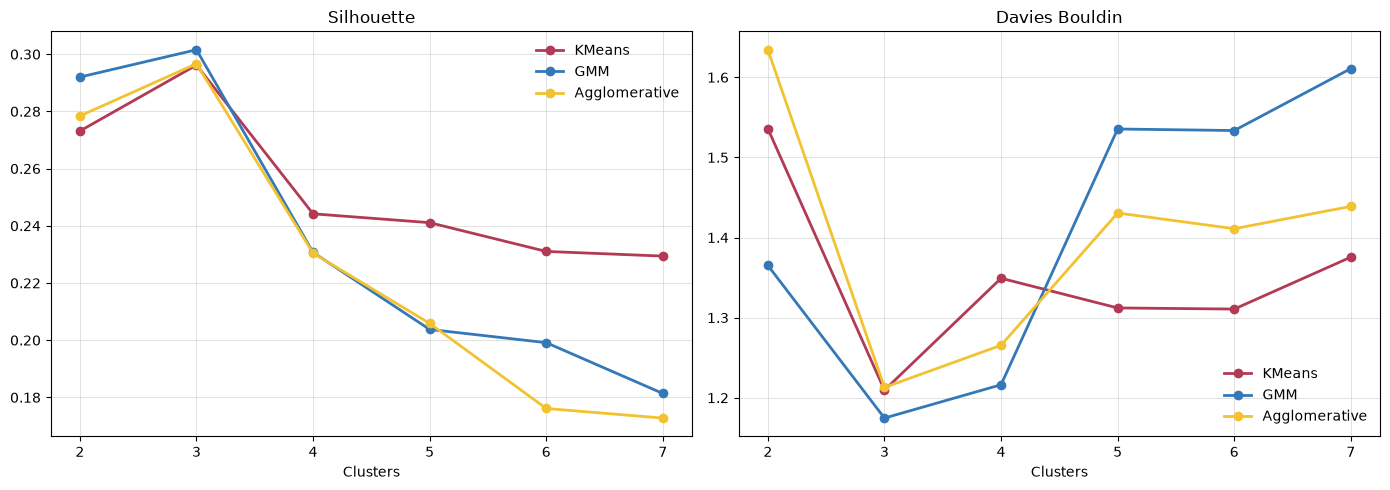

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metric_types = ['Silhouette', 'Davies Bouldin']
gmm_metrics_tied_df = gmm_metrics_df.loc[gmm_metrics_df['cov'] == 'tied']

colors = {
    'KMeans': '#B23A55',
    'GMM': '#3478B8',
    'Agglomerative': '#F2C230'
}

for ax, col in zip(axes, metric_types):
    ax.plot(km_metrics_df['k'], km_metrics_df[col], marker='o', color=colors['KMeans'], linewidth=2, markersize=6, label='KMeans')
    ax.plot(gmm_metrics_tied_df['k'], gmm_metrics_tied_df[col], marker='o', color=colors['GMM'], linewidth=2, markersize=6, label='GMM')
    ax.plot(agglo_metrics_df['k'], agglo_metrics_df[col], marker='o', color=colors['Agglomerative'], linewidth=2, markersize=6, label='Agglomerative')

    ax.grid(True, color='lightgrey', linewidth=0.7, alpha=0.7)

    ax.set_xlabel("Clusters")
    ax.set_title(col)
    ax.legend(frameon=False)

plt.tight_layout()
plt.show()

#### **PCA Visualization** 

Principal Component Analysis (PCA) was used to project the seven standardized features onto two dimensions. Each model's three-cluster assignment is displayed in the same PCA space, making their visual structure easier to compare.

In [13]:
# Fit all models
kmeans = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE)
cleaned_data["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

gmm = GaussianMixture(n_components=3, covariance_type="tied", n_init=20, random_state=RANDOM_STATE)
cleaned_data["gmm_cluster"] = gmm.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
cleaned_data["agglo_cluster"] = agglo.fit_predict(X_scaled)

# PCA projection to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

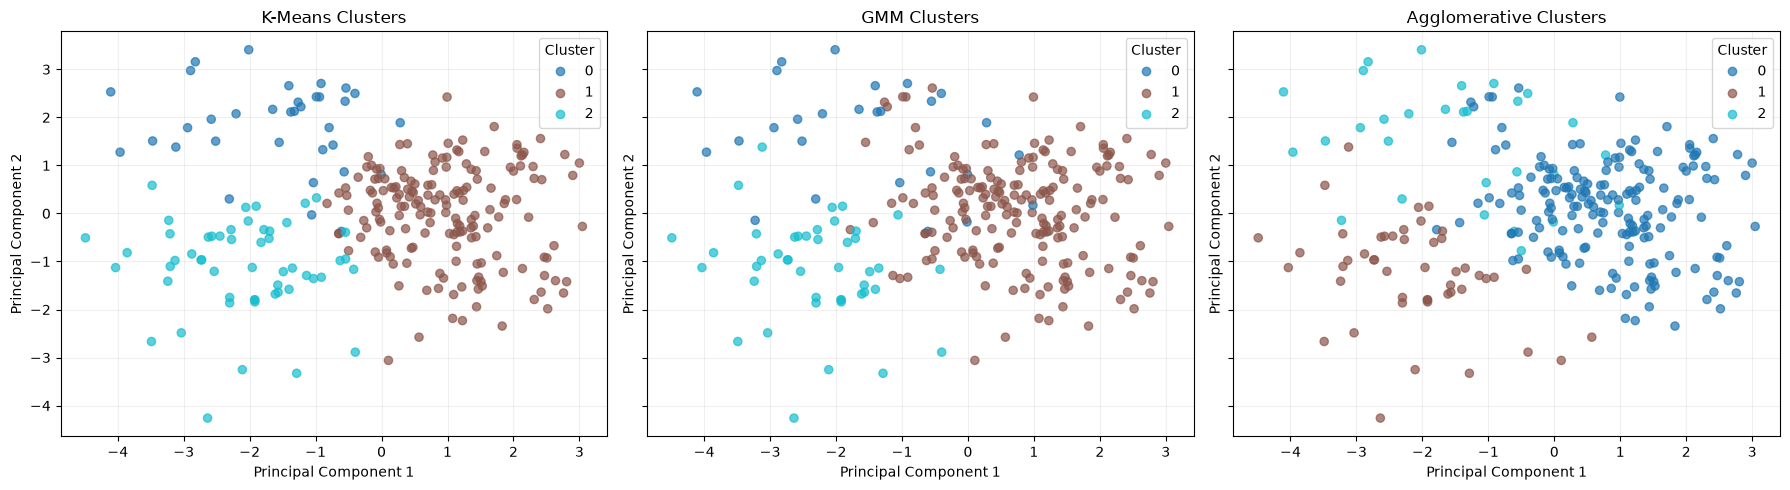

,K-Means,GMM,Agglomerative
0,34,27,179
1,169,185,48
2,53,44,29


In [14]:
# Visualize each model's clusters using PCA
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

models = {
    "K-Means": "kmeans_cluster",
    "GMM": "gmm_cluster",
    "Agglomerative": "agglo_cluster"
}

for ax, (name, cluster_col) in zip(axes, models.items()):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=cleaned_data[cluster_col],
        cmap="tab10",
        alpha=0.7,
        s=35
    )

    ax.set_title(f"{name} Clusters")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Compare cluster sizes across models
model_cols = {
    "K-Means": "kmeans_cluster",
    "GMM": "gmm_cluster",
    "Agglomerative": "agglo_cluster"
}

pd.DataFrame({
    name: cleaned_data[col].value_counts().sort_index()
    for name, col in model_cols.items()
})

#### **Model Selection**

Of the methods evaluated, the three-component **GMM** with tied covariance was selected for interpretation. This model choice was due to its performance but overall the three models perform relatively the same on the optimal three cluster threshold once tuned. 

- Highest Silhouette score (**0.30**)
- Lowest Davies–Bouldin index (**1.17**)


**Cluster Attributes and Interpretation**

In [15]:
# Reverse log transformations
profile_data = cleaned_data.copy()
profile_data[log_features] = np.expm1(profile_data[log_features])

# Calculate median values in original units
profile = profile_data.groupby("gmm_cluster")[selected_features].median().T

# Include number of facilities in each cluster
profile.loc["n_facilities"] = (
    profile_data["gmm_cluster"].value_counts().sort_index()
)

profile.round(2)


gmm_cluster,0,1,2
sizerank_numeric,5.00,5.00,3.00
facility_size_sqft,"500,000.00","1,460,000.00","149,305.00"
property_size_acres,53.00,275.00,15.00
generator_count,87.00,10.00,25.50
summer_Cents/kWh.1,22.74,11.40,9.51
summer_Megawatthours.1,"6,104,953.18","4,441,624.98","6,136,570.47"
Capacity_Sum,"3,370.30","1,536.00","1,524.45"
n_facilities,27.00,185.00,44.00


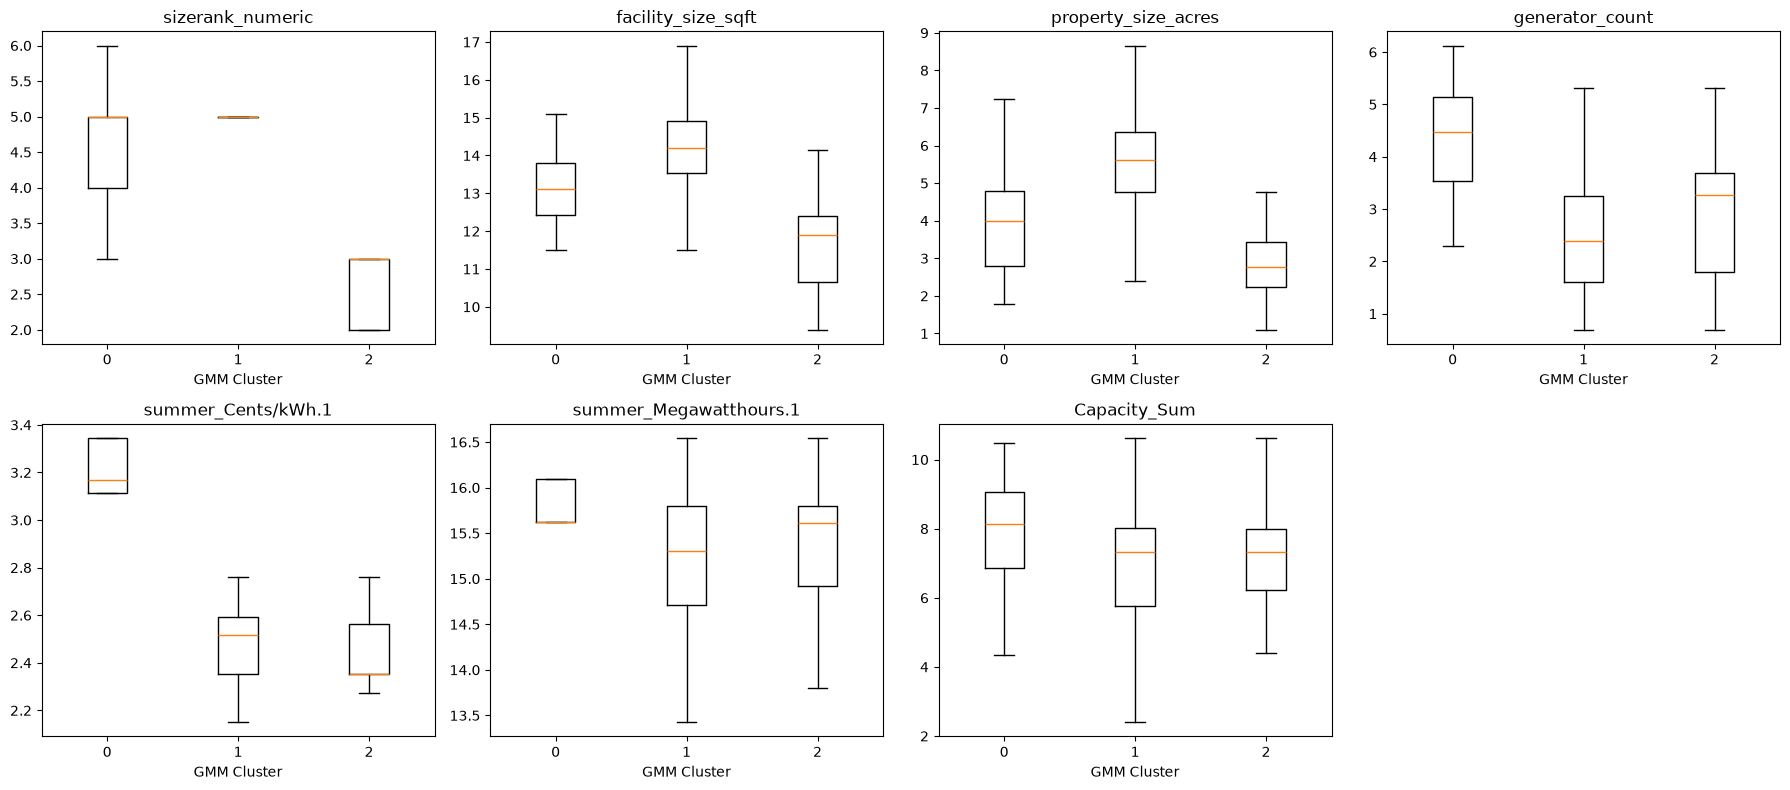

In [16]:
clusters = sorted(cleaned_data["gmm_cluster"].unique())

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

# Box plots for each selected feature
for ax, col in zip(axes.flat, selected_features):
    data = [cleaned_data.loc[cleaned_data["gmm_cluster"] == c, col] for c in clusters]
    ax.boxplot(data, tick_labels=clusters, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("GMM Cluster")

# Hide unused plots
for ax in axes.flat[len(selected_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

#### **Results**

The clusters may suggest the following dataset-specific groupings:

- **Cluster 0 (27 facilities):** Medium-sized facilities with substantial surrounding energy infrastructure.

- **Cluster 1 (185 facilities):** Large facilities with fewer nearby generators and lower electric cost. 

- **Cluster 2 (44 facilities):** Smaller facilities with limited capacity but high regional electricity consumption.

These results suggest that facility size, surrounding energy infrastructure, and electricity prices may help distinguish different data center groupings. These different clusters may represent the different types of data centers that are created based on location. For example, larger facilities may be built in remote locations where land is more affordable, whereas smaller to mid-sized facilities are built in areas where land is expensive. This could provide some explanation to why there is less nearby energy infrastructure and lower energy cost associated with larger facilities.